---
## 0. Imports and Setup

In [1]:
import os, time, csv, itertools, warnings
warnings.filterwarnings('ignore')

# ── Directories ───────────────────────────────────────────────────────────────
for d in ['../figures/circuits', '../figures/benchmarks', '../figures/slides', '../results']:
    os.makedirs(d, exist_ok=True)

# ── Qiskit 2.x ────────────────────────────────────────────────────────────────
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.primitives import StatevectorSampler, StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp, Statevector
import qiskit

# ── PennyLane ─────────────────────────────────────────────────────────────────
import pennylane as qml
from pennylane import numpy as pnp

# ── Scientific ────────────────────────────────────────────────────────────────
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

print(f"Qiskit    : {qiskit.__version__}")
print(f"PennyLane : {qml.__version__}")
print("Setup complete.")

Qiskit    : 2.5.0
PennyLane : 0.45.0
Setup complete.


---
## 1. Graph Construction and MaxCut Formulation

Graph: 6 nodes, 7 edges
Edges: [(0, 1), (0, 5), (1, 2), (1, 3), (2, 4), (3, 5), (4, 5)]


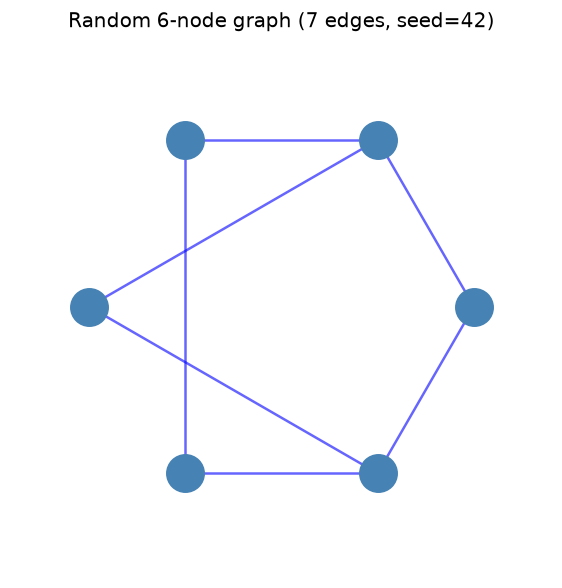

Saved: figures/circuits/qaoa_graph.png


In [2]:
# ── Random 6-node graph ───────────────────────────────────────────────────────
np.random.seed(42)
n_nodes = 6

# Erdos-Renyi graph: each edge present with probability p=0.5
edges = []
for i in range(n_nodes):
    for j in range(i + 1, n_nodes):
        if np.random.rand() < 0.5:
            edges.append((i, j))

print(f"Graph: {n_nodes} nodes, {len(edges)} edges")
print(f"Edges: {edges}")

# ── Visualise graph ───────────────────────────────────────────────────────────
# Manual layout (no networkx needed)
angles = np.linspace(0, 2 * np.pi, n_nodes, endpoint=False)
pos    = {i: (np.cos(a), np.sin(a)) for i, a in enumerate(angles)}

fig, ax = plt.subplots(figsize=(5, 5))
for (u, v) in edges:
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]],
            'b-', linewidth=1.5, alpha=0.6)
for node, (x, y) in pos.items():
    ax.scatter(x, y, s=500, c='steelblue', zorder=5)
    ax.text(x, y, str(node), ha='center', va='center',
            color='white', fontsize=12, fontweight='bold')
ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
ax.set_aspect('equal'); ax.axis('off')
ax.set_title(f'Random 6-node graph ({len(edges)} edges, seed=42)', fontsize=12)
plt.tight_layout()
plt.savefig('../figures/circuits/qaoa_graph.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved: figures/circuits/qaoa_graph.png")

In [3]:
# ── MaxCut Hamiltonian: H_C = 1/2 * sum_{(i,j) in E} (I - Zi Zj) ────────────
def maxcut_hamiltonian(n: int, edges: list) -> SparsePauliOp:
    """
    Build MaxCut cost Hamiltonian as SparsePauliOp.
    H_C = 0.5 * sum_{(i,j) in E} (I - Zi Zj)
    Maximising <H_C> maximises the number of cut edges.
    """
    pauli_list = []
    for (i, j) in edges:
        # Identity term (constant 0.5 per edge)
        pauli_str_I   = 'I' * n
        pauli_list.append((pauli_str_I, 0.5))

        # -0.5 * Zi Zj  (Qiskit ordering: index 0 = rightmost character)
        pauli_str_ZZ = list('I' * n)
        pauli_str_ZZ[i] = 'Z'
        pauli_str_ZZ[j] = 'Z'
        pauli_list.append((''.join(pauli_str_ZZ), -0.5))

    return SparsePauliOp.from_list(pauli_list).simplify()


H_maxcut = maxcut_hamiltonian(n_nodes, edges)
print("MaxCut Hamiltonian:")
print(H_maxcut)
print(f"\nNumber of Pauli terms : {len(H_maxcut)}")
print(f"Number of qubits      : {H_maxcut.num_qubits}")
print(f"Maximum eigenvalue    : {max(np.linalg.eigvalsh(H_maxcut.to_matrix())):.1f}")

MaxCut Hamiltonian:
SparsePauliOp(['IIIIII', 'ZZIIII', 'ZIIIIZ', 'IZZIII', 'IZIZII', 'IIZIZI', 'IIIZIZ', 'IIIIZZ'],
              coeffs=[ 3.5+0.j, -0.5+0.j, -0.5+0.j, -0.5+0.j, -0.5+0.j, -0.5+0.j, -0.5+0.j,
 -0.5+0.j])

Number of Pauli terms : 8
Number of qubits      : 6
Maximum eigenvalue    : 6.0


In [4]:
# ── Classical brute-force (ground truth for small graphs) ─────────────────────
def brute_force_maxcut(n: int, edges: list) -> dict:
    """Enumerate all 2^n partitions; O(2^n) — only feasible for n <= 20."""
    best_cut  = 0
    best_part = None
    for bits in range(2 ** n):
        cut = sum(1 for (i, j) in edges
                  if ((bits >> i) & 1) != ((bits >> j) & 1))
        if cut > best_cut:
            best_cut  = cut
            best_part = bits
    partition = format(best_part, f'0{n}b')
    return {'max_cut': best_cut, 'partition': partition, 'optimal_bits': best_part}


t0 = time.perf_counter()
bf = brute_force_maxcut(n_nodes, edges)
t_bf_ms = (time.perf_counter() - t0) * 1000

print(f"Brute-force MaxCut result:")
print(f"  Max cut size : {bf['max_cut']} edges (out of {len(edges)})")
print(f"  Partition    : {bf['partition']}")
print(f"  Runtime      : {t_bf_ms:.3f} ms")

Brute-force MaxCut result:
  Max cut size : 6 edges (out of 7)
  Partition    : 001101
  Runtime      : 0.176 ms


In [5]:
# ── Greedy heuristic ──────────────────────────────────────────────────────────
def greedy_maxcut(n: int, edges: list) -> dict:
    """
    Simple greedy: assign each node to the set that maximises current cut.
    O(n * |E|). Approximation ratio: 0.5 guaranteed (better in practice).
    """
    partition = [0] * n
    for v in range(n):
        # Count cut edges if v in set 0 vs set 1
        cut0 = sum(1 for (i, j) in edges if (i == v or j == v)
                   and partition[i if j == v else j] == 1)
        cut1 = sum(1 for (i, j) in edges if (i == v or j == v)
                   and partition[i if j == v else j] == 0)
        partition[v] = 0 if cut0 >= cut1 else 1

    cut_size = sum(1 for (i, j) in edges if partition[i] != partition[j])
    return {'max_cut': cut_size, 'partition': ''.join(map(str, partition))}


t0 = time.perf_counter()
gr = greedy_maxcut(n_nodes, edges)
t_gr_ms = (time.perf_counter() - t0) * 1000

print(f"Greedy MaxCut result:")
print(f"  Cut size          : {gr['max_cut']} (optimal: {bf['max_cut']})")
print(f"  Approx. ratio     : {gr['max_cut'] / bf['max_cut']:.3f}")
print(f"  Runtime           : {t_gr_ms:.3f} ms")

Greedy MaxCut result:
  Cut size          : 5 (optimal: 6)
  Approx. ratio     : 0.833
  Runtime           : 0.135 ms


---
## 2. QAOA Circuit Construction

In [6]:
def qaoa_circuit(n: int, edges: list, p: int) -> QuantumCircuit:
    """
    Build p-layer QAOA circuit for MaxCut.

    Parameters
    ----------
    n     : number of qubits (= nodes)
    edges : list of (i,j) graph edges
    p     : number of QAOA layers

    Returns parameterised QuantumCircuit with 2p parameters [gamma_0..p-1, beta_0..p-1].

    Circuit structure:
      1. Hadamard layer: prepare |+>^n
      2. For each layer k = 0..p-1:
         a. Cost unitary:  for each edge (i,j): CNOT(i,j) + Rz(2*gamma_k, j) + CNOT(i,j)
         b. Mixer unitary: for each qubit i:    Rx(2*beta_k, i)
    """
    gamma = ParameterVector('gamma', p)
    beta  = ParameterVector('beta',  p)
    qc    = QuantumCircuit(n, name=f'QAOA(p={p})')

    # Initial state: uniform superposition
    qc.h(range(n))
    qc.barrier()

    for k in range(p):
        # ── Cost unitary: e^{-i * gamma_k * H_C} ─────────────────────────────
        # For each edge (i,j): implements e^{i*gamma*Zi*Zj/2}
        # via: CNOT(i,j) -> Rz(2*gamma, j) -> CNOT(i,j)
        for (i, j) in edges:
            qc.cx(i, j)
            qc.rz(2 * gamma[k], j)
            qc.cx(i, j)
        qc.barrier()

        # ── Mixer unitary: e^{-i * beta_k * H_B} ─────────────────────────────
        # H_B = sum_i X_i  =>  e^{-i*beta*X} = Rx(2*beta)
        for i in range(n):
            qc.rx(2 * beta[k], i)
        qc.barrier()

    return qc


qc_p1 = qaoa_circuit(n_nodes, edges, p=1)
print("QAOA circuit (p=1):")
print(qc_p1.draw('text', fold=120))
print(f"\nDepth      : {qc_p1.depth()}")
print(f"Parameters : {qc_p1.num_parameters} (gamma + beta)")
print(f"Gates      : {dict(qc_p1.count_ops())}")

QAOA circuit (p=1):
     ┌───┐ ░                                                                                          »
q_0: ┤ H ├─░───■──────────────────────■────■────────────────────────────────────────■─────────────────»
     ├───┤ ░ ┌─┴─┐┌────────────────┐┌─┴─┐  │                                        │                 »
q_1: ┤ H ├─░─┤ X ├┤ Rz(2*gamma[0]) ├┤ X ├──┼──────────■─────────────────────────────┼────■────■───────»
     ├───┤ ░ └───┘└────────────────┘└───┘  │        ┌─┴─┐       ┌────────────────┐  │  ┌─┴─┐  │       »
q_2: ┤ H ├─░───────────────────────────────┼────────┤ X ├───────┤ Rz(2*gamma[0]) ├──┼──┤ X ├──┼────■──»
     ├───┤ ░                               │        └───┘       └────────────────┘  │  └───┘┌─┴─┐  │  »
q_3: ┤ H ├─░───────────────────────────────┼────────────────────────────────────────┼───────┤ X ├──┼──»
     ├───┤ ░                               │                                        │       └───┘┌─┴─┐»
q_4: ┤ H ├─░───────────────────────────────┼

In [7]:
# ── Save circuit diagram ──────────────────────────────────────────────────────
fig = qc_p1.draw('mpl', fold=120, style='clifford')
if fig is not None:
    fig.savefig('../figures/circuits/qaoa_p1_circuit.png', bbox_inches='tight', dpi=150)
    print("Saved: figures/circuits/qaoa_p1_circuit.png")

print(f"\nCircuit summary (p=1, {n_nodes} qubits, {len(edges)} edges):")
for p in [1, 2, 3]:
    qc = qaoa_circuit(n_nodes, edges, p=p)
    cx_count = qc.count_ops().get('cx', 0)
    print(f"  p={p}: depth={qc.depth()}, CNOT count={cx_count}, params={qc.num_parameters}")

Saved: figures/circuits/qaoa_p1_circuit.png

Circuit summary (p=1, 6 qubits, 7 edges):
  p=1: depth=17, CNOT count=14, params=2
  p=2: depth=33, CNOT count=28, params=4
  p=3: depth=49, CNOT count=42, params=6


---
## 3. QAOA Energy Evaluation with V2 Primitives

In [8]:
def qaoa_energy(params: np.ndarray, n: int, edges: list, p: int,
                estimator: StatevectorEstimator,
                hamiltonian: SparsePauliOp) -> float:
    """
    Evaluate QAOA energy <psi(gamma,beta)|H_C|psi(gamma,beta)> using
    Qiskit 2.x V2 StatevectorEstimator primitive.

    params: flat array [gamma_0, ..., gamma_{p-1}, beta_0, ..., beta_{p-1}]
    """
    qc     = qaoa_circuit(n, edges, p)
    # Split params: first p are gammas, last p are betas
    param_dict = dict(zip(qc.parameters, params))
    bound_qc   = qc.assign_parameters(param_dict)

    pub    = (bound_qc, hamiltonian)
    result = estimator.run([pub]).result()
    return float(result[0].data.evs)


# Quick test at gamma=pi/4, beta=pi/8
estimator = StatevectorEstimator()
test_params = np.array([np.pi / 4, np.pi / 8])   # p=1: [gamma, beta]
test_energy = qaoa_energy(test_params, n_nodes, edges, p=1, estimator=estimator, hamiltonian=H_maxcut)
print(f"Test energy at (gamma=pi/4, beta=pi/8): {test_energy:.4f}")
print(f"Max possible cut (brute force)        : {bf['max_cut']}")
print(f"Approximation ratio (test point)      : {test_energy / bf['max_cut']:.4f}")

Test energy at (gamma=pi/4, beta=pi/8): 3.2500
Max possible cut (brute force)        : 6
Approximation ratio (test point)      : 0.5417


---
## 4. Parameter Landscape (p=1)

For p=1, the two-dimensional landscape $\langle H_C \rangle(\gamma, \beta)$ can be visualised directly. This reveals the structure that higher-p QAOA tries to exploit.

Scanning 30x30 = 900 parameter points...
Done in 2.14s | Max energy found: 4.4948


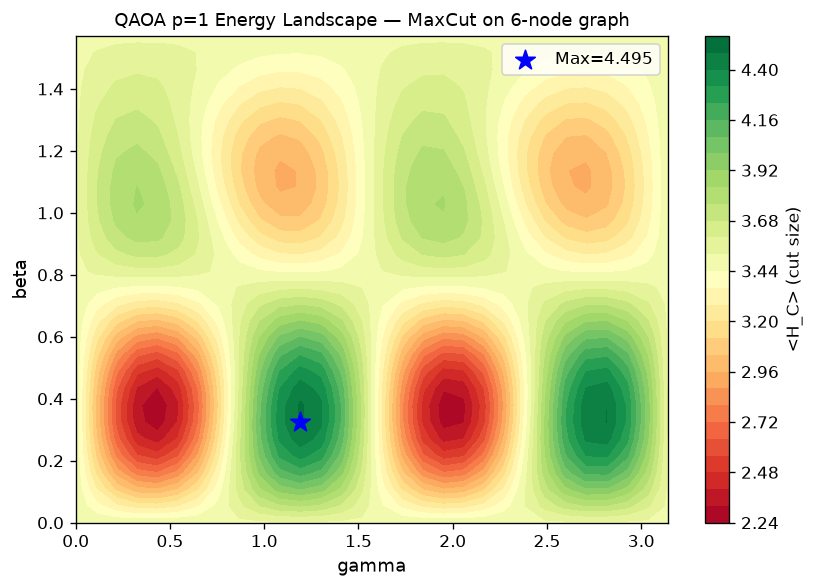

Saved: figures/benchmarks/qaoa_p1_landscape.png
Best landscape point: gamma=1.192, beta=0.325


In [9]:
# ── 2D parameter landscape scan (p=1) ────────────────────────────────────────
N_grid   = 30
gammas   = np.linspace(0, np.pi, N_grid)
betas    = np.linspace(0, np.pi / 2, N_grid)
energy_grid = np.zeros((N_grid, N_grid))

print(f"Scanning {N_grid}x{N_grid} = {N_grid**2} parameter points...")
t0 = time.perf_counter()

qc_p1 = qaoa_circuit(n_nodes, edges, p=1)
# Batch all PUBs for efficiency
pubs = []
for i, g in enumerate(gammas):
    for j, b in enumerate(betas):
        params = dict(zip(qc_p1.parameters, [g, b]))
        pubs.append((qc_p1.assign_parameters(params), H_maxcut))

batch_results = estimator.run(pubs).result()

for k, res in enumerate(batch_results):
    i, j = divmod(k, N_grid)
    energy_grid[i, j] = float(res.data.evs)

elapsed = time.perf_counter() - t0
print(f"Done in {elapsed:.2f}s | Max energy found: {energy_grid.max():.4f}")

# ── Contour plot ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))
G, B = np.meshgrid(gammas, betas, indexing='ij')
cf   = ax.contourf(G, B, energy_grid, levels=30, cmap='RdYlGn')
plt.colorbar(cf, ax=ax, label='<H_C> (cut size)')

# Mark optimal point
idx_max = np.unravel_index(np.argmax(energy_grid), energy_grid.shape)
ax.scatter(gammas[idx_max[0]], betas[idx_max[1]], s=150, c='blue',
           zorder=5, marker='*', label=f'Max={energy_grid.max():.3f}')
ax.set_xlabel('gamma', fontsize=11)
ax.set_ylabel('beta',  fontsize=11)
ax.set_title(f'QAOA p=1 Energy Landscape — MaxCut on {n_nodes}-node graph', fontsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('../figures/benchmarks/qaoa_p1_landscape.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved: figures/benchmarks/qaoa_p1_landscape.png")
print(f"Best landscape point: gamma={gammas[idx_max[0]]:.3f}, beta={betas[idx_max[1]]:.3f}")

---
## 5. QAOA Optimisation for p = 1, 2, 3

In [10]:
def run_qaoa(n: int, edges: list, p: int, n_runs: int = 5) -> dict:
    """
    Run QAOA with COBYLA optimiser, multiple random restarts.
    Returns best energy and corresponding parameters.
    """
    estimator_  = StatevectorEstimator()
    H           = maxcut_hamiltonian(n, edges)
    best_energy = -np.inf
    best_params = None
    histories   = []

    for run in range(n_runs):
        np.random.seed(run * 7)
        x0    = np.random.uniform(0, np.pi, 2 * p)
        hist  = []

        def neg_energy(params):
            e = qaoa_energy(params, n, edges, p,
                            estimator=estimator_, hamiltonian=H)
            hist.append(e)
            return -e   # COBYLA minimises

        res = minimize(neg_energy, x0, method='COBYLA',
                       options={'maxiter': 200, 'rhobeg': 0.5})
        E   = -res.fun
        histories.append(hist)
        if E > best_energy:
            best_energy = E
            best_params = res.x

    return {'energy': best_energy, 'params': best_params, 'histories': histories}


qaoa_results = {}
opt_bf = bf['max_cut']

for p in [1, 2, 3]:
    print(f"Optimising QAOA p={p} (5 restarts)...", end=' ', flush=True)
    t0  = time.perf_counter()
    res = run_qaoa(n_nodes, edges, p, n_runs=5)
    res['runtime_s'] = time.perf_counter() - t0
    qaoa_results[p]  = res
    ratio = res['energy'] / opt_bf
    print(f"E = {res['energy']:.4f} | ratio = {ratio:.4f} | {res['runtime_s']:.1f}s")

print(f"\nBrute-force optimum : {opt_bf} edges")
print(f"Greedy heuristic    : {gr['max_cut']} edges (ratio {gr['max_cut']/opt_bf:.4f})")

Optimising QAOA p=1 (5 restarts)... E = 4.5011 | ratio = 0.7502 | 1.2s
Optimising QAOA p=2 (5 restarts)... E = 4.7426 | ratio = 0.7904 | 5.2s
Optimising QAOA p=3 (5 restarts)... E = 4.8860 | ratio = 0.8143 | 10.9s

Brute-force optimum : 6 edges
Greedy heuristic    : 5 edges (ratio 0.8333)


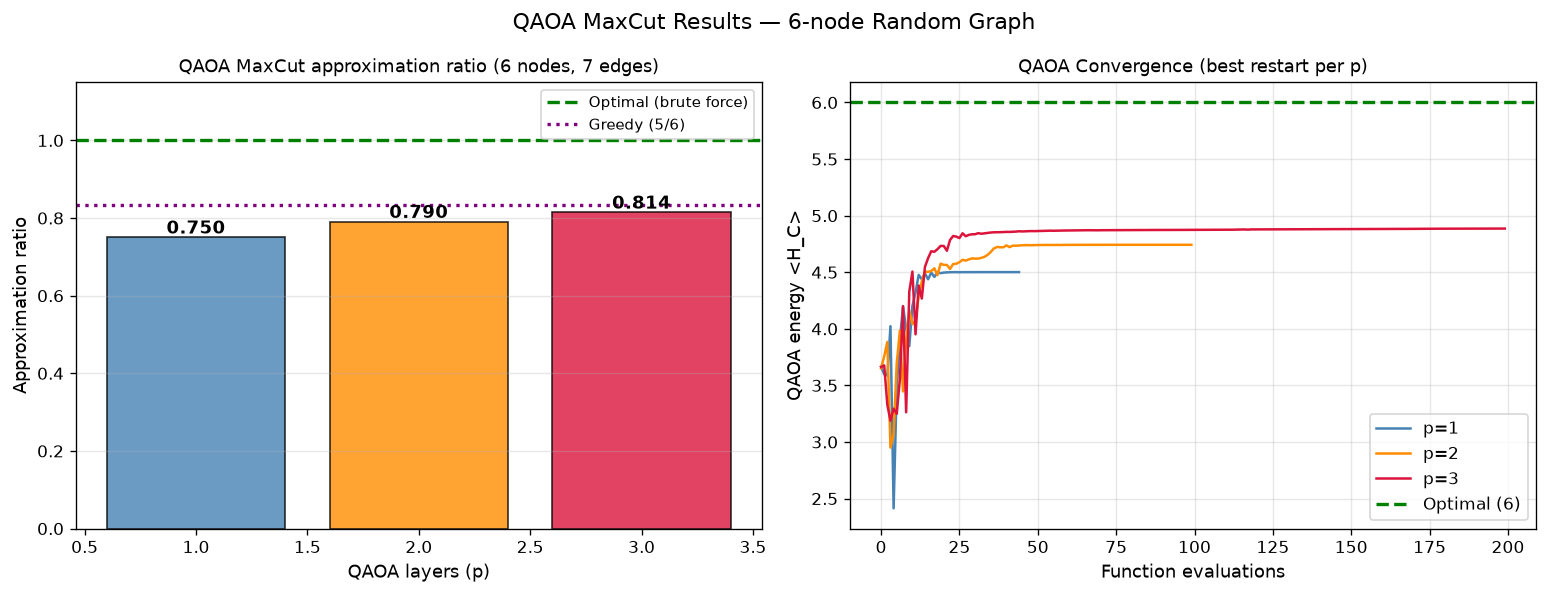

Saved: figures/benchmarks/qaoa_results.png


In [11]:
# ── Approximation ratio vs p plot ─────────────────────────────────────────────
p_values = [1, 2, 3]
ratios   = [qaoa_results[p]['energy'] / opt_bf for p in p_values]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: approximation ratio
axes[0].bar(p_values, ratios, color=['steelblue', 'darkorange', 'crimson'],
            alpha=0.8, edgecolor='black')
axes[0].axhline(1.0,                 linestyle='--', color='green', linewidth=2,
                label='Optimal (brute force)')
axes[0].axhline(gr['max_cut']/opt_bf, linestyle=':',  color='purple', linewidth=2,
                label=f'Greedy ({gr["max_cut"]}/{opt_bf})')
for i, (p, r) in enumerate(zip(p_values, ratios)):
    axes[0].text(p, r + 0.01, f'{r:.3f}', ha='center', fontsize=11, fontweight='bold')
axes[0].set_xlabel('QAOA layers (p)', fontsize=11)
axes[0].set_ylabel('Approximation ratio', fontsize=11)
axes[0].set_title(f'QAOA MaxCut approximation ratio ({n_nodes} nodes, {len(edges)} edges)', fontsize=11)
axes[0].set_ylim(0, 1.15)
axes[0].legend(fontsize=9)
axes[0].grid(True, axis='y', alpha=0.3)

# Right: convergence histories for best run of each p
colors_p = {1: 'steelblue', 2: 'darkorange', 3: 'crimson'}
for p in p_values:
    best_hist = max(qaoa_results[p]['histories'], key=lambda h: max(h) if h else -np.inf)
    axes[1].plot(best_hist, label=f'p={p}', color=colors_p[p], linewidth=1.5)

axes[1].axhline(opt_bf, linestyle='--', color='green', linewidth=2, label=f'Optimal ({opt_bf})')
axes[1].set_xlabel('Function evaluations', fontsize=11)
axes[1].set_ylabel('QAOA energy <H_C>', fontsize=11)
axes[1].set_title('QAOA Convergence (best restart per p)', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.suptitle('QAOA MaxCut Results — 6-node Random Graph', fontsize=13)
plt.tight_layout()
plt.savefig('../figures/benchmarks/qaoa_results.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved: figures/benchmarks/qaoa_results.png")

---
## 6. Solution Sampling — Reading the QAOA Bitstrings

In [12]:
def sample_qaoa_solution(n: int, edges: list, p: int, params: np.ndarray,
                          shots: int = 2048) -> dict:
    """
    Sample the QAOA circuit with optimal parameters using StatevectorSampler.
    Returns cut sizes for each sampled bitstring.
    """
    sampler  = StatevectorSampler()
    qc       = qaoa_circuit(n, edges, p)
    qc_meas  = qc.copy()
    qc_meas.measure_all()

    param_dict = dict(zip(qc.parameters, params))
    bound_qc   = qc_meas.assign_parameters(param_dict)

    job    = sampler.run([bound_qc], shots=shots)
    counts = job.result()[0].data.meas.get_counts()

    # Evaluate cut size for each bitstring
    cut_for_bitstring = {}
    for bits, count in counts.items():
        # Qiskit: bits[0] = qubit 0 (little-endian from MSB of string)
        # bits is returned as string with qubit 0 on the RIGHT
        partition = [int(b) for b in reversed(bits)]
        cut = sum(1 for (i, j) in edges if partition[i] != partition[j])
        cut_for_bitstring[bits] = (count, cut)

    return cut_for_bitstring


# Use best p=3 result
best_p      = max(qaoa_results, key=lambda p: qaoa_results[p]['energy'])
best_params = qaoa_results[best_p]['params']
print(f"Sampling with best result: p={best_p}")

sample_dist = sample_qaoa_solution(n_nodes, edges, best_p, best_params, shots=4096)

# Sort by cut size
sorted_by_cut = sorted(sample_dist.items(), key=lambda x: x[1][1], reverse=True)

print(f"\nTop 10 sampled bitstrings:")
print(f"{'Bitstring':>12} | {'Count':>6} | {'Prob':>6} | {'Cut size':>9}")
print("-" * 40)
total_shots = sum(v[0] for v in sample_dist.values())
for bs, (cnt, cut) in sorted_by_cut[:10]:
    opt_mark = ' ← OPTIMAL' if cut == bf['max_cut'] else ''
    print(f"  {bs:>10} | {cnt:>6} | {cnt/total_shots:>6.3f} | {cut:>9}{opt_mark}")

# Probability of sampling an optimal solution
p_optimal = sum(cnt for bs, (cnt, cut) in sample_dist.items()
                if cut == bf['max_cut']) / total_shots
print(f"\nP(optimal cut = {bf['max_cut']}) = {p_optimal:.3f}")

Sampling with best result: p=3

Top 10 sampled bitstrings:
   Bitstring |  Count |   Prob |  Cut size
----------------------------------------
      011001 |    552 |  0.135 |         6 ← OPTIMAL
      100010 |    336 |  0.082 |         6 ← OPTIMAL
      001101 |    546 |  0.133 |         6 ← OPTIMAL
      110010 |    529 |  0.129 |         6 ← OPTIMAL
      011101 |    329 |  0.080 |         6 ← OPTIMAL
      100110 |    602 |  0.147 |         6 ← OPTIMAL
      011011 |     53 |  0.013 |         5
      100101 |    182 |  0.044 |         5
      010011 |    200 |  0.049 |         5
      011010 |    164 |  0.040 |         5

P(optimal cut = 6) = 0.707


---
## 7. PennyLane QAOA Implementation

In [14]:
dev_qaoa = qml.device('default.qubit', wires=n_nodes)

def cost_hamiltonian_pl(n: int, edges: list):
    """Build MaxCut cost Hamiltonian as PennyLane operator."""
    coeffs = []
    obs    = []
    for (i, j) in edges:
        # -0.5 * Zi Zj
        coeffs.append(-0.5)
        obs.append(qml.PauliZ(i) @ qml.PauliZ(j))
        # +0.5 * I
        coeffs.append(0.5)
        obs.append(qml.Identity(i))
    return qml.Hamiltonian(coeffs, obs)


H_cost_pl   = cost_hamiltonian_pl(n_nodes, edges)
H_mixer_pl  = qml.Hamiltonian(
    [1.0] * n_nodes,
    [qml.PauliX(i) for i in range(n_nodes)]
)


@qml.qnode(dev_qaoa, interface='autograd')
def qaoa_circuit_pl(params, n_layers):
    """PennyLane QAOA circuit using built-in QAOA layer."""
    gammas = params[:n_layers]
    betas  = params[n_layers:]

    # Initial state
    for i in range(n_nodes):
        qml.Hadamard(wires=i)

    # QAOA layers
    for k in range(n_layers):
        qml.qaoa.cost_layer(gammas[k],   H_cost_pl)
        qml.qaoa.mixer_layer(betas[k],   H_mixer_pl)

    return qml.expval(H_cost_pl)


print("PennyLane QAOA circuit (p=1):")
test_pl = pnp.array([np.pi / 4, np.pi / 8], requires_grad=True)

print(qml.draw(qaoa_circuit_pl)(test_pl, n_layers=1))

PennyLane QAOA circuit (p=1):
0: ──H ···
1: ──H ···
2: ──H ···
3: ──H ···
4: ──H ···
5: ──H ···

0: ··· ─╭ApproxTimeEvolution(-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,0.79) ···
1: ··· ─├ApproxTimeEvolution(-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,0.79) ···
2: ··· ─├ApproxTimeEvolution(-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,0.79) ···
3: ··· ─├ApproxTimeEvolution(-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,0.79) ···
4: ··· ─├ApproxTimeEvolution(-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,0.79) ···
5: ··· ─╰ApproxTimeEvolution(-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,-0.50,0.50,0.79) ···

0: ··· ─╭ApproxTimeEvolution(1.00,1.00,1.00,1.00,1.00,1.00,0.39)─┤ ╭<𝓗>
1: ··· ─├ApproxTimeEvolution(1.00,1.00,1.00,1.00,1.00,1.00,0.39)─┤ ├<𝓗>
2: ··· ─├ApproxTimeEvolution(1.00,1.00,1.00,1.00,1.00,1.00,0.3

In [15]:
# ── PennyLane VQE-style optimisation for p=1 ─────────────────────────────────
pnp.random.seed(42)
p_pl       = 1
params_pl  = pnp.array(np.random.uniform(0, np.pi, 2 * p_pl), requires_grad=True)
opt_pl     = qml.GradientDescentOptimizer(stepsize=0.3)
history_pl = []

t0 = time.perf_counter()
for step in range(120):
    params_pl, e = opt_pl.step_and_cost(lambda p: -qaoa_circuit_pl(p, n_layers=p_pl), params_pl)
    history_pl.append(-float(e))
    if step % 30 == 0:
        print(f"  Step {step:>4} | E = {-float(e):.4f}")

rt_pl   = time.perf_counter() - t0
final_pl = float(qaoa_circuit_pl(params_pl, n_layers=p_pl))
print(f"\nFinal PL energy : {final_pl:.4f}")
print(f"Approx. ratio   : {final_pl / opt_bf:.4f}")
print(f"Runtime         : {rt_pl:.2f}s")

  Step    0 | E = 2.9698
  Step   30 | E = 2.6594
  Step   60 | E = 3.6850
  Step   90 | E = 3.6850

Final PL energy : 3.6850
Approx. ratio   : 0.6142
Runtime         : 3.05s


---
## 8. Comparison Summary

In [16]:
print("MaxCut Results Summary — 6-node Graph")
print("=" * 70)
print(f"{'Method':<30} | {'Cut value':>10} | {'Approx ratio':>13} | {'Runtime':>10}")
print("-" * 70)
print(f"{'Brute force (exact)':<30} | {opt_bf:>10} | {'1.0000 (OPT)':>13} | {t_bf_ms:>9.2f}ms")
print(f"{'Greedy heuristic':<30} | {gr['max_cut']:>10} | {gr['max_cut']/opt_bf:>13.4f} | {t_gr_ms:>9.2f}ms")
for p in [1, 2, 3]:
    r   = qaoa_results[p]
    rt  = r['runtime_s'] * 1000
    rat = r['energy'] / opt_bf
    print(f"{'QAOA Qiskit p=' + str(p):<30} | {r['energy']:>10.4f} | {rat:>13.4f} | {rt:>9.1f}ms")
print(f"{'QAOA PennyLane p=1':<30} | {final_pl:>10.4f} | {final_pl/opt_bf:>13.4f} | {rt_pl*1000:>9.1f}ms")
print("=" * 70)

MaxCut Results Summary — 6-node Graph
Method                         |  Cut value |  Approx ratio |    Runtime
----------------------------------------------------------------------
Brute force (exact)            |          6 |  1.0000 (OPT) |      0.18ms
Greedy heuristic               |          5 |        0.8333 |      0.14ms
QAOA Qiskit p=1                |     4.5011 |        0.7502 |    1198.8ms
QAOA Qiskit p=2                |     4.7426 |        0.7904 |    5157.1ms
QAOA Qiskit p=3                |     4.8860 |        0.8143 |   10883.1ms
QAOA PennyLane p=1             |     3.6850 |        0.6142 |    3047.5ms


---
## 9. Scaling Analysis

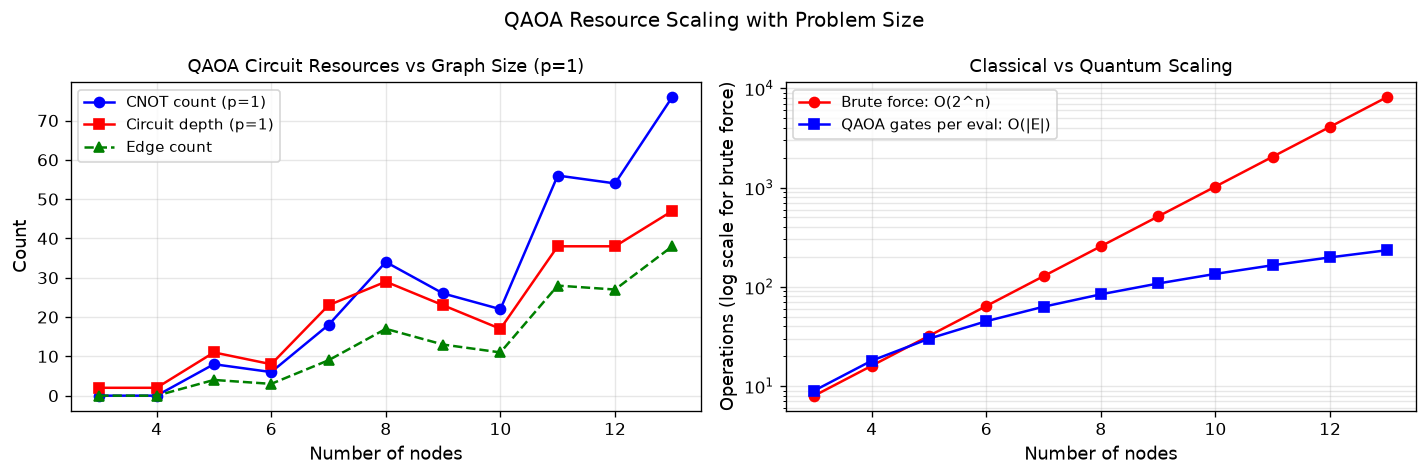

In [17]:
# ── How does QAOA scale with graph size? ──────────────────────────────────────
# Number of parameters, CNOT gates, and circuit depth vs n_nodes (fixed edge density)
edge_density = 0.4
node_range   = list(range(3, 14))
metrics_scale = {'nodes': [], 'edges': [], 'params_p1': [], 'cnots_p1': [], 'depth_p1': []}

np.random.seed(0)
for n in node_range:
    # Generate random edges at fixed density
    e = [(i, j) for i in range(n) for j in range(i+1, n)
         if np.random.rand() < edge_density]
    qc = qaoa_circuit(n, e, p=1)
    metrics_scale['nodes'].append(n)
    metrics_scale['edges'].append(len(e))
    metrics_scale['params_p1'].append(qc.num_parameters)
    metrics_scale['cnots_p1'].append(qc.count_ops().get('cx', 0))
    metrics_scale['depth_p1'].append(qc.depth())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(metrics_scale['nodes'], metrics_scale['cnots_p1'], 'b-o', label='CNOT count (p=1)')
axes[0].plot(metrics_scale['nodes'], metrics_scale['depth_p1'],  'r-s', label='Circuit depth (p=1)')
axes[0].plot(metrics_scale['nodes'], metrics_scale['edges'],     'g--^', label='Edge count')
axes[0].set_xlabel('Number of nodes', fontsize=11)
axes[0].set_ylabel('Count', fontsize=11)
axes[0].set_title('QAOA Circuit Resources vs Graph Size (p=1)', fontsize=11)
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# Brute-force scaling
bf_ops = [2**n for n in node_range]
axes[1].semilogy(node_range, bf_ops, 'r-o', label='Brute force: O(2^n)')
# QAOA evaluations per optimisation step (quadratic in n for dense graphs)
qaoa_ops = [n*(n-1)//2 * 3 for n in node_range]  # ~3 gates per edge per layer
axes[1].plot(node_range, qaoa_ops, 'b-s', label='QAOA gates per eval: O(|E|)')
axes[1].set_xlabel('Number of nodes', fontsize=11)
axes[1].set_ylabel('Operations (log scale for brute force)', fontsize=11)
axes[1].set_title('Classical vs Quantum Scaling', fontsize=11)
axes[1].legend(fontsize=9)
axes[1].grid(True, which='both', alpha=0.3)

plt.suptitle('QAOA Resource Scaling with Problem Size', fontsize=12)
plt.tight_layout()
plt.savefig('../figures/benchmarks/qaoa_scaling.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 10. Benchmarking Record

In [18]:
benchmarks_file = '../results/benchmarks.csv'
write_header    = not os.path.exists(benchmarks_file)

fieldnames = [
    'notebook', 'problem', 'dataset', 'classical_baseline',
    'quantum_method', 'framework', 'n_qubits', 'circuit_depth',
    'cnot_count', 'simulator', 'metric', 'quantum_result',
    'classical_result', 'runtime_quantum_ms', 'runtime_classical_ms', 'notes'
]

records = []
for p in [1, 2, 3]:
    r      = qaoa_results[p]
    qc_p   = qaoa_circuit(n_nodes, edges, p)
    ratio  = r['energy'] / opt_bf
    records.append({
        'notebook'             : '04_qaoa_maxcut',
        'problem'              : f'MaxCut on 6-node random graph ({len(edges)} edges)',
        'dataset'              : f'{n_nodes}-node Erdos-Renyi graph, edge prob=0.5, seed=42',
        'classical_baseline'   : f'Brute force: {opt_bf} edges; Greedy: {gr["max_cut"]} edges',
        'quantum_method'       : f'QAOA p={p} (COBYLA, 5 restarts)',
        'framework'            : 'Qiskit 2.x (StatevectorEstimator + Sampler V2)',
        'n_qubits'             : n_nodes,
        'circuit_depth'        : qc_p.depth(),
        'cnot_count'           : qc_p.count_ops().get('cx', 0),
        'simulator'            : 'StatevectorEstimator (noiseless)',
        'metric'               : 'Approximation ratio (expected cut / optimal cut)',
        'quantum_result'       : f'{r["energy"]:.4f} (ratio={ratio:.4f})',
        'classical_result'     : f'{opt_bf} edges (ratio=1.0000)',
        'runtime_quantum_ms'   : round(r['runtime_s'] * 1000, 1),
        'runtime_classical_ms' : round(t_bf_ms, 3),
        'notes'                : (
            f'P(optimal sample)={p_optimal:.3f}. '
            f'Greedy ratio={gr["max_cut"]/opt_bf:.3f}. '
            f'QAOA p={p} ratio={ratio:.3f}. '
            'QAOA V2 Primitive batch evaluation used for landscape scan.'
        )
    })

with open(benchmarks_file, 'a', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    if write_header:
        writer.writeheader()
    writer.writerows(records)

print(f"Appended {len(records)} records to {benchmarks_file}")
print(f"\nFinal summary:")
print(f"  Graph       : {n_nodes} nodes, {len(edges)} edges")
print(f"  Optimal cut : {opt_bf}")
print(f"  Greedy      : {gr['max_cut']} (ratio {gr['max_cut']/opt_bf:.3f})")
for p in [1, 2, 3]:
    r = qaoa_results[p]
    print(f"  QAOA p={p}    : {r['energy']:.4f} (ratio {r['energy']/opt_bf:.3f})")

Appended 3 records to ../results/benchmarks.csv

Final summary:
  Graph       : 6 nodes, 7 edges
  Optimal cut : 6
  Greedy      : 5 (ratio 0.833)
  QAOA p=1    : 4.5011 (ratio 0.750)
  QAOA p=2    : 4.7426 (ratio 0.790)
  QAOA p=3    : 4.8860 (ratio 0.814)
